# Lesson 3 — The design equation and one design situation

A code does not tell the engineer to provide "a mean resistance of 2.4".
It gives a **design equation**: characteristic values, partial factors
and combination rules. The engineer provides exactly the resistance the
equation demands, and the reliability that results is whatever it is.
Calibration turns this around: it computes the resulting reliability for
many typical designs and adjusts the partial factors until it meets the
target.

The building block is one **design situation**: a failure mode (material
and mechanism), a dominating variable load, and the proportions of the
loads. This lesson takes one of the 810 situations of the AHG model
apart.

In [1]:
import os
import sys

import numpy as np

try:
    import codecal as cc
except ImportError:
    sys.path.insert(0, os.path.abspath('..'))
    import codecal as cc
from codecal import plots
from codecal.plots import Figure

FIG = 'figures'
os.makedirs(FIG, exist_ok=True)


def save(fig, name):
    """Save a figure next to the lesson and show it (inline in Jupyter/Spyder)."""
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches='tight')
    try:
        from IPython.display import display
        display(fig)
    except ImportError:            # plain python: the PNG in figures/ is the output
        pass


model = cc.ahg_model(n_mcs=1_000_000)

## 1. One design situation

Steel bending under wind, with 80 % of the permanent load being
self-weight ($a_G = 0.8$) and the variable load making up half of the
characteristic load ($a_Q = 0.5$). The seven random variables:

In [2]:
steel = next(m for m in model.failure_modes if m.name == 'Steel bending')
wind = next(l for l in model.loads if l.name == 'wind')
s = cc.DesignSituation(steel, wind, a_G=0.8, a_Q=0.5, weight=1.0, model=model)
for name, v in zip(s.variable_names, s.variables):
    print(f"  {name:4s} {v}")

  Θ_R  Θ_R steel bending: Lognormal(mean=1.15, CoV=0.05), x_k=1
  R    Steel yield strength: Lognormal(mean=1, CoV=0.05), x_k=0.83
  Θ_E  Load-effect model uncertainty: Lognormal(mean=1, CoV=0.1), x_k=1
  G    Self-weight steel: Normal(mean=1, CoV=0.025), x_k=1
  P    Permanent load (other than self-weight): Normal(mean=1, CoV=0.1), x_k=1
  Θ_Q  Wind model uncertainty: Lognormal(mean=0.97, CoV=0.26), x_k=1
  Q    Wind, 50-year maximum: Gumbel(mean=1, CoV=0.14), x_k=1.08


## 2. The design equation gives the design parameter $z$

EN 1990 eq. 8.12 (the former 6.10) for this situation reads

$$ \frac{z\,\theta_{R,k}\,r_k}{\gamma_M} =
   (1 - a_Q)\big[a_G\,\gamma_G\,g_k + (1 - a_G)\,\gamma_{G,P}\,p_k\big] + a_Q\,\gamma_Q\,q_k . $$

Everything on the right is known once the partial factors are chosen; the
left side is the design resistance. $z$ is the amount of mean resistance
per unit of mean load that the engineer ends up providing. With the
current Eurocode values $\gamma_G = 1.35$, $\gamma_Q = 1.5$:

In [3]:
pf = cc.START_VALUES
z = s.design_parameter(pf, '8.12')
print(f"γ_G = {pf.gamma_G}, γ_Q = {pf.gamma_Q_of('wind')}, γ_M = {steel.gamma_M}")
print(f"characteristic values: θ_R,k = {steel.theta_R.char}, r_k = {steel.R.char}, "
      f"g_k = {steel.G.char}, p_k = {model.P.char}, q_k = {wind.Q.char:.3f}")
print(f"design parameter z = {z:.4f}")

γ_G = 1.35, γ_Q = 1.5, γ_M = 1.0
characteristic values: θ_R,k = 1.0, r_k = 0.83, g_k = 1.0, p_k = 1.0, q_k = 1.084
design parameter z = 1.7924


## 3. The limit state and its reliability

With $z$ fixed, the structure fails when

$$ g = z\,\Theta_R\,R - \Theta_E\big[(1 - a_Q)(a_G\,G + (1 - a_G)\,P) + a_Q\,\Theta_Q\,Q\big] \le 0 . $$

All seven variables have mean 1 (the loads: mean of the 50-year maximum).
FORM gives the reliability index of this design:

In [4]:
ls = s.limit_state(z)
res = cc.form(ls)
print(f"β = {res.beta:.3f}   (P_f ≈ {res.pf:.2e} in 50 years),  {res.iterations} iterations")
print("sensitivities α² :", res.sensitivities(s.variable_names))
print("design point x*  :", {n: round(float(v), 3) for n, v in zip(s.variable_names, res.x_star)})

β = 3.573   (P_f ≈ 1.77e-04 in 50 years),  11 iterations
sensitivities α² : {'Θ_R': 0.0385, 'R': 0.0385, 'Θ_E': 0.1533, 'G': 0.0005, 'P': 0.0005, 'Θ_Q': 0.4946, 'Q': 0.2741}
design point x*  : {'Θ_R': 1.109, 'R': 0.964, 'Θ_E': 1.144, 'G': 1.002, 'P': 1.008, 'Θ_Q': 1.785, 'Q': 1.315}


Two things to notice:

* β is below the target 3.8 — with the current factors this steel beam
  under wind is on the low side, as the AHG study found.
* Three variables carry almost all the uncertainty: the wind model
  uncertainty $\Theta_Q$, the wind load $Q$ itself and the load-effect
  model uncertainty $\Theta_E$. The steel strength hardly matters
  (CoV 0.05). The design point shows the "most likely failure": the
  wind model uncertainty at 1.8 (its mean is 0.97) and the wind load
  30 % above its mean 50-year maximum, while the resistance side sits
  close to its means.

## 4. What the partial factors do

Raising $\gamma_Q$ raises $z$ and thus β. The slope is the currency of
calibration: how much β per unit of γ.

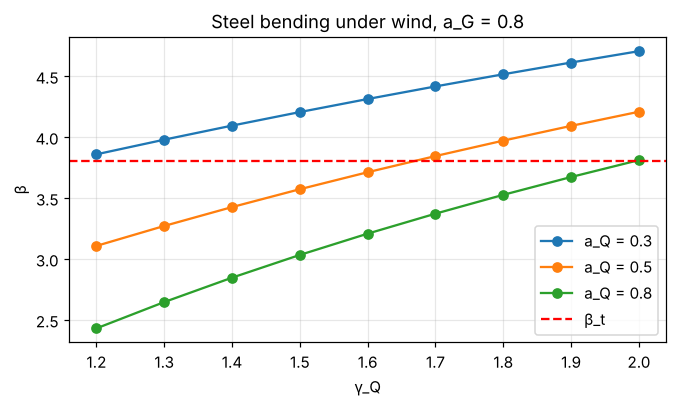

In [5]:
gammas_Q = np.linspace(1.2, 2.0, 9)
fig = Figure(figsize=(7, 3.6))
ax = fig.subplots()
for a_Q in (0.3, 0.5, 0.8):
    s_a = cc.DesignSituation(steel, wind, a_G=0.8, a_Q=a_Q, weight=1.0, model=model)
    betas = [s_a.reliability(pf.with_values(['gamma_Q'], [g]), '8.12')[0] for g in gammas_Q]
    ax.plot(gammas_Q, betas, 'o-', label=f'a_Q = {a_Q}')
ax.axhline(3.8, color='r', ls='--', label='β_t')
ax.set_xlabel('γ_Q')
ax.set_ylabel('β')
ax.set_title('Steel bending under wind, a_G = 0.8')
ax.grid(alpha=0.3)
ax.legend()
save(fig, 'lesson03_beta_vs_gammaQ.png')

The more the variable load dominates ($a_Q$ large), the more $\gamma_Q$
helps — and the lower β is with the present values. For $a_Q = 0.3$,
$\gamma_Q$ is almost irrelevant; there $\gamma_G$ is the lever. A single
pair of factors cannot make all designs equally reliable; it can only
make them reliable *enough on average* — hence the weighted objective of
lesson 5.

## 5. The three design equations

EN 1990:2023 offers three fundamental combinations. Eq. 8.12 uses the
full variable load with the full permanent load. The two-combination
rules take the less favourable of two expressions: in 8.13 the variable
load is reduced by $\psi_0$ in the first and the permanent load by $\xi$
in the second; in 8.14 the first expression has no variable load at all.

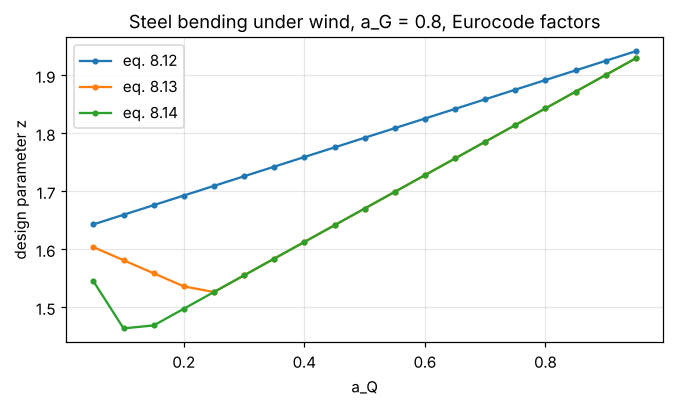

In [6]:
a_Qs = np.linspace(0.05, 0.95, 19)
fig = Figure(figsize=(7, 3.6))
ax = fig.subplots()
for eq in ('8.12', '8.13', '8.14'):
    zs = [cc.DesignSituation(steel, wind, 0.8, a, 1.0, model).design_parameter(pf, eq) for a in a_Qs]
    ax.plot(a_Qs, zs, 'o-', ms=3, label=f'eq. {eq}')
ax.set_xlabel('a_Q')
ax.set_ylabel('design parameter z')
ax.set_title('Steel bending under wind, a_G = 0.8, Eurocode factors')
ax.grid(alpha=0.3)
ax.legend()
save(fig, 'lesson03_z_vs_equation.png')

With the present $\xi = 0.85$ and $\psi_0 = 0.6$, eqs. 8.13 and 8.14
demand less resistance than 8.12 at every load ratio — which is why a
calibration of 8.13/8.14 also has to decide on $\xi$.

## Exercises

1. Repeat section 3 for concrete bending under imposed load. Which
   variables dominate there?
2. For the steel/wind situation, find by hand the $\gamma_Q$ that gives
   β = 3.8 at $a_Q = 0.5$ (use `scipy.optimize.brentq`).
3. Set the wind model uncertainty's CoV to 0.15 instead of 0.26 (build a
   new `rv` and `VariableLoad`) and see what happens to β and α². This is
   the single most influential assumption of the whole AHG model.